# Full port-operability method: 1979-2025, by continent

This is the **full-study notebook**, not the Cape Town pilot. It uses all **4,013 saved offshore ERA5 positions**, preserving the inspected coverage (no Greenland or Antarctica), and all nine sensitivity scenarios. The agreed endpoint is **31 December 2025**: no incomplete 2026 year is included.

Two independently conditioned study windows are produced from the same hourly observations:

- `paper_1979_2018`: the paper's original time window, on the reconstructed grid.
- `extended_1979_2025`: the 47-year extension using complete calendar years.

Sources: [Wiegel et al. (2021), section 2 and Appendix A](literature/jmse-09-00695-v2.pdf), [Wiegel's thesis](literature/MSc_Thesis_Matijs_Wiegel_Mapping_port_operability_indicators_across_the_world_final.pdf), and [paper DOI](https://doi.org/10.3390/jmse9070695). Scientific calculations are shared with [port_operability.py](port_operability.py); [full_study.py](full_study.py) provides continent-sized acquisition and resumable analysis. The earlier pilot notebook and its results are not overwritten.

**Africa extraction is paused.** Downloads and analysis are disabled. The 19 old Africa tile payloads were removed at user request; pilot and static inputs are retained. Run All performs preparation only. Continental GRIB benchmarks succeeded, but the legacy 5-degree downloader has not yet been replaced: see the [measured strategy comparison](data/benchmarks/era5-access/strategy-summary.json) before enabling any bulk retrieval.

## 1. Configuration: select the continent(s) to download

Change `SELECTED_CONTINENTS` to e.g. `["Europe"]`, `["Africa", "Asia"]`, or leave all six. Complete one region, change the selection, and rerun: monthly files and completed site analyses are reused.

1. Run preparation and inspect the request/storage table.
2. Set a sufficient `REQUEST_BUDGET` and `RUN_DOWNLOAD = True` only when ready.
3. If retaining raw responses is too expensive, explicitly set `DISCARD_NEW_RAW = True`. This removes **only newly downloaded responses**, after the complete paired-point month has been saved and checked; public requests and hashes are retained. Pre-existing raw files are left untouched.
4. After the selected region's months are downloaded, set `RUN_ANALYSIS = True`.

All downloaded scientific data and results remain under `data/`. The CDS token stays outside the repository in `~/.cdsapirc`; dataset terms must already be accepted. Select the repository `.venv` kernel (see [README](README.md)).

In [1]:
%matplotlib inline
import calendar
import importlib.metadata
import json
import shutil
import sys
from dataclasses import asdict
from pathlib import Path

REPOSITORY_ROOT = Path.cwd().parent if Path.cwd().name == 'archive' else Path.cwd()
sys.path.insert(0, str(REPOSITORY_ROOT))

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

import port_operability as model
import full_study as full

DATA_ROOT = REPOSITORY_ROOT / "data"
RUN_ROOT = DATA_ROOT / "full-method-1979-2025"
GRID_FILE = DATA_ROOT / "processed" / "coastal-grid.geojson"
YEARS = list(range(1979, 2026))
SELECTED_CONTINENTS = ["Africa"]
RUN_DOWNLOAD = False
RUN_ANALYSIS = False
REQUEST_BUDGET = 37788
DISCARD_NEW_RAW = True
ANALYSIS_BATCH_SIZE = 8
SAVE_HOURLY_INDICATORS = False
IG_MAX_PERIOD = 40.0
SCENARIOS = model.SCENARIOS
PERIODS = full.PERIODS
PREPARED = RUN_ROOT / "prepared"
FIGURES = RUN_ROOT / "figures"
PREPARED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})
RISK_COLOURS = {"Low": "#00cc00", "Medium": "#ffff33", "High": "#ff7f50", "Very high": "#d73027"}
INDICATOR_COLOURS = {"wind": "#00a390", "short_wave": "#eb7245", "ig": "#c41e79"}
scope = "Global" if set(SELECTED_CONTINENTS) == set(full.CONTINENTS) else ", ".join(SELECTED_CONTINENTS)
print("Scope:", scope, "| 1979-2025 inclusive | nine scenarios")
print("Interpreter:", sys.executable)
print("Download enabled:", RUN_DOWNLOAD, "| analysis enabled:", RUN_ANALYSIS)

/Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Scope: Africa | 1979-2025 inclusive | nine scenarios
Interpreter: /Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/bin/python
Download enabled: False | analysis enabled: False


## 2. Load the frozen grid and assign continent download groups

The saved GeoJSON is the authoritative input; this notebook never regenerates the positions. Nearest-country assignments use each point's **coastline anchor**, not an offshore point across a strait, with periodic longitude handling.

Groups follow Natural Earth's `CONTINENT` country attribute, not a new geographical border model. For example, Russia is grouped under Europe and Indonesia under Asia. These are download/processing labels only: they do not alter any coordinate, metocean calculation, or global total. Inspect the exported assignments before downloading.

The original manually adjusted 4,560-point selection remains unavailable. Grid counts are not forced to agree with the publication.

In [2]:
grid_geo = gpd.read_file(GRID_FILE)
countries_file = model.download_reference(
    "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip",
    DATA_ROOT / "reference" / "ne_110m_admin_0_countries.zip",
)
countries = gpd.read_file(countries_file)
grid = full.assign_continents(grid_geo, countries)
if len(grid) != 4013:
    raise ValueError("The inspected 4,013-point grid changed; review its provenance before continuing.")
if not SELECTED_CONTINENTS or not set(SELECTED_CONTINENTS) <= set(full.CONTINENTS):
    raise ValueError(f"Select from {full.CONTINENTS}")
selected_sites = grid.loc[grid.continent.isin(SELECTED_CONTINENTS)].copy()
grid.to_csv(PREPARED / "continent-grid.csv", index=False)
model.export_points(grid, PREPARED / "continent-grid.geojson",
                    "Frozen offshore ERA5 grid with country-based continent download groups; no operability values.")
continent_counts = grid.groupby("continent").size().rename("sites")
display(continent_counts.to_frame())
print("Selected sites:", len(selected_sites), "| all saved sites:", len(grid))
validation_ports = model.select_port_sites(grid)
validation_ports.to_csv(PREPARED / "validation-port-sites.csv", index=False)
display(validation_ports[["name", "site_id", "lon", "lat", "port_to_grid_km"]])

,sites
continent,
Africa,513
Asia,1190
Europe,738
North America,723
Oceania,472
South America,377


Selected sites: 513 | all saved sites: 4013


,name,site_id,lon,lat,port_to_grid_km
0,Doraleh,6122,43.5,11.5,47.087891
1,Jeddah,7342,39.0,21.5,16.703081
2,Hay Point,2241,149.5,-21.0,37.411304
3,Shanghai,8277,122.0,32.0,81.588617
4,Hadera,8312,34.5,32.5,34.864636
5,Long Beach,8386,-118.0,33.5,34.462942
6,Tomakomai,9287,141.5,42.0,70.744232
7,Salalah,6687,54.0,16.5,50.037717
8,Cape Town,1643,18.0,-34.0,40.903524
9,Geraldton,1830,114.5,-29.0,26.328986


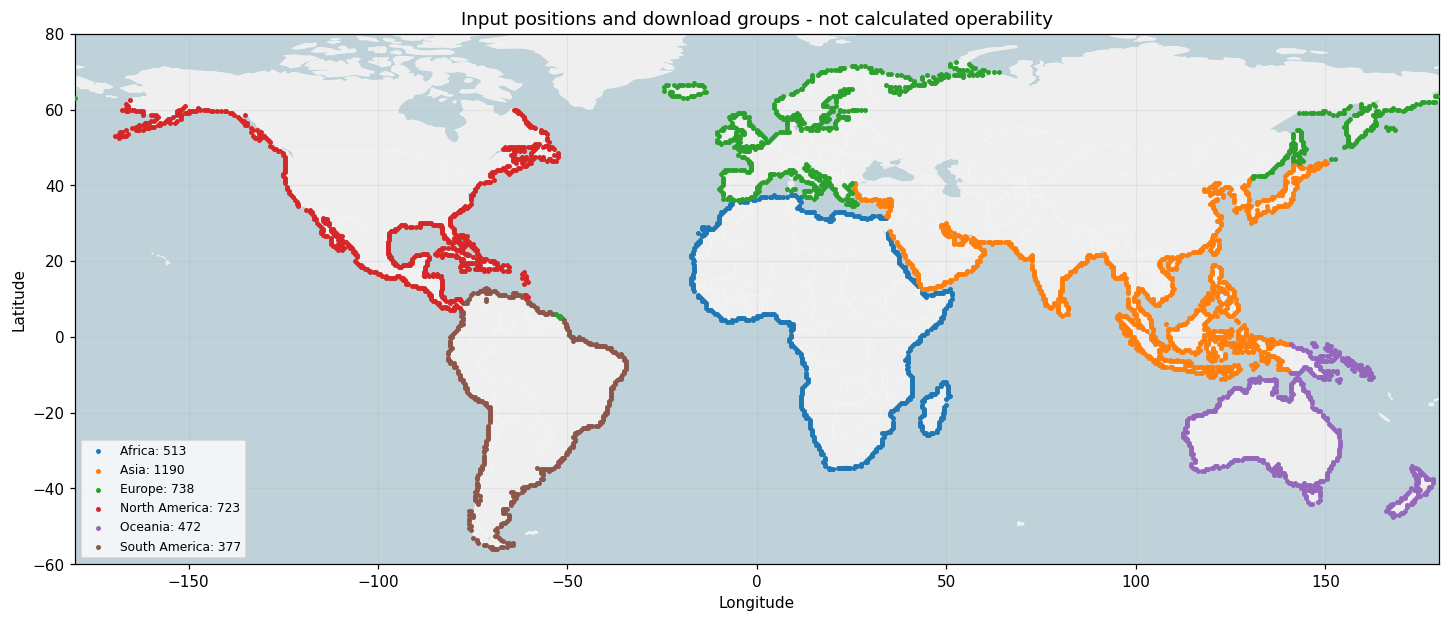

In [3]:
def world_axes(ax):
    countries.plot(ax=ax, facecolor="#eeefee", edgecolor="white", linewidth=.25)
    ax.set(facecolor="#bfd2d9", xlim=(-180, 180), ylim=(-60, 80),
           xlabel="Longitude", ylabel="Latitude", aspect="equal")

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{'-'.join(SELECTED_CONTINENTS).replace(' ', '-')}-{name}.png",
                dpi=140, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(16, 8))
world_axes(ax)
for continent, group in grid.groupby("continent"):
    ax.scatter(group.lon, group.lat, s=5, label=f"{continent}: {len(group)}", zorder=3)
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Input positions and download groups - not calculated operability")
save_figure(fig, "input-continents")
plt.show()

## 3. Resource plan: real hourly data, monthly requests, no hidden global execution

Six variables are downloaded: `u10`, `v10`, `swh`, `mwd`, `mwp`, `pp1d`. Bathymetry and normals are already in the frozen grid. Requests use the pilot-tested 5-degree regional tiles and individual months because a full-year request exceeded CDS cost limits.

This is a substantial archival extraction, potentially hundreds of thousands of CDS requests. Request counts are conservative upper bounds before reusing retained raw responses. Sizes assume uncompressed float32; the raw estimate includes both a response and a possible extracted NetCDF copy. Queue duration and compression are not predicted.

Unlike the pilot's per-point files, the full workflow stores **one paired-point NetCDF per continent/month**, avoiding millions of small files. All six groups over 47 years require 3,384 monthly files. Monthly cache metadata is checked against the selected grid, variables, coordinates and all expected hours.

Raw-retention mode may exceed available space. `DISCARD_NEW_RAW = True` reduces retained storage to the point caches plus one working month; this is opt-in. Baseline hourly *derived* indicators are also opt-in because they add substantial storage. Exact request and disk guards run again before any CDS retrieval.

In [4]:
resource_plan = full.download_estimate(grid, SELECTED_CONTINENTS, YEARS, RUN_ROOT)
resource_plan.to_csv(PREPARED / "download-estimate.csv", index=False)
display(resource_plan)
print("Pending requests, upper bound:", f"{resource_plan.pending_requests_upper_bound.sum():,}")
print("Additional paired-point cache, uncompressed GiB:", round(resource_plan.point_cache_gib.sum(), 1))
print("Additional retained raw/extraction GiB:", round(resource_plan.raw_and_extraction_gib.sum(), 1))
print("Current free GiB:", round(shutil.disk_usage(DATA_ROOT).free / 1024**3, 1))
print("Raw deletion policy:", "new responses discarded after verified extraction" if DISCARD_NEW_RAW else "retain raw responses")
preparation_manifest = {
    "years": YEARS, "periods": PERIODS, "selected_continents": SELECTED_CONTINENTS,
    "grid_sha256": model.file_hash(GRID_FILE), "grid_digest": full.grid_digest(grid),
    "countries_sha256": model.file_hash(countries_file),
    "scenarios": [asdict(s) for s in SCENARIOS], "download_enabled_at_preparation": RUN_DOWNLOAD,
    "exact_original_grid": False, "original_103_port_sample_available": False,
}
model.write_json(PREPARED / "preparation.json", preparation_manifest)

,continent,sites,months,cached_months,pending_requests_upper_bound,point_cache_gib,raw_and_extraction_gib,monthly_working_gib
0,Africa,513,564,0,37788,4.724266,149.31629,0.269634


Pending requests, upper bound: 37,788
Additional paired-point cache, uncompressed GiB: 4.7
Additional retained raw/extraction GiB: 149.3
Current free GiB: 134.7
Raw deletion policy: new responses discarded after verified extraction


In [5]:
if RUN_DOWNLOAD:
    full.download_continents(
        grid, SELECTED_CONTINENTS, YEARS, DATA_ROOT, RUN_ROOT,
        request_budget=REQUEST_BUDGET, discard_new_raw=DISCARD_NEW_RAW,
    )
else:
    print("NOT RUN: global/continent hourly downloads are disabled. Review the plan before enabling RUN_DOWNLOAD.")

NOT RUN: global/continent hourly downloads are disabled. Review the plan before enabling RUN_DOWNLOAD.


## 4. Scientific method and explicit reconstruction limits

1. Wind magnitude: `sqrt(u10**2 + v10**2)`.
2. Solve linear dispersion `omega**2 = g*k*tanh(k*h)`. Shoal by `Ks=sqrt(Cg_off/Cg_near)`, refract by Snell's law, impose the original `Kr >= 0.8` bound and breaking cap `Hs <= 0.73*h`.
3. Apply the shoreward-direction filter only to short waves. IG calculations use all-direction shoaled wave heights, as in the original implementation.
4. Rebuild bound IG waves using Appendix A's difference-interaction kernel, a normalized JONSWAP spectrum and directional integration over the 0.004-0.04 Hz IG band.
5. Apply individual and joint thresholds. Fill only interior calm gaps of at most four observed hours. Missing hours split events; endpoints are not forced calm. Derive conditional availability, merged-event frequency/duration, raw availability, p50 and p95.
6. Repeat for the original-period and extended-period windows, all years, four seasons and all nine scenarios.

**Missing originals are not invented:** the original IG lookup, gamma(Hs,Tp) implementation, manual coastal exclusions and 103-port identifiers were not supplied. The reconstruction uses fixed JONSWAP gamma 3.3; spreading s=7 for Tp>10 s, otherwise 2; 192 primary frequencies, 72 directions and 19 IG frequencies. Quadrature refinement checks numerical sensitivity, not agreement with the missing original lookup.

For global storm states the lookup is extended to the largest breaking-limited scenario height (14.6 m at 20 m depth) and Tp=40 s, with the original 0.05 m / 0.1 s increments. Out-of-domain states still **raise**, never clip; increase the configured period bound explicitly if observations require it. Offshore bathymetry shallower than the target depth is floored as in the legacy model, an acknowledged limitation.

The output is **potential metocean availability before port interventions**, not measured downtime. Short-wave percentiles use shoreward observations only. Event boundary corrections, consistent merged-event statistics and the corrected sediment-angle proxy are not claimed to replicate legacy bugs.

In [6]:
display(pd.DataFrame([asdict(s) for s in SCENARIOS]))
if RUN_ANALYSIS:
    quadrature = []
    for tp in [5, 10, 15]:
        coarse = model.bound_ig_unit(tp)
        refined = model.bound_ig_unit(tp, n_frequency=384, n_direction=144, n_ig=37)
        quadrature.append({"Tp": tp, "relative_height_difference": abs(coarse[0] / refined[0] - 1)})
    quadrature = pd.DataFrame(quadrature)
    if not quadrature.relative_height_difference.lt(.02).all():
        raise ArithmeticError("IG quadrature refinement exceeds the accepted 2% height difference.")
    display(quadrature)
    quadrature.to_csv(PREPARED / "ig-quadrature.csv", index=False)
else:
    print("NOT RUN: IG quadrature/lookups and scientific analysis remain disabled.")

,name,depth_m,wind_limit,wave_limit,ig_limit,wind_factor,wave_factor,gap_hours
0,baseline,20.0,13.8,2.0,0.05,1.00,1.00,4
1,lower_thresholds,20.0,10.8,1.5,0.04,1.00,1.00,4
2,higher_thresholds,20.0,17.2,2.5,0.06,1.00,1.00,4
3,depth_17m,17.0,13.8,2.0,0.05,1.00,1.00,4
4,depth_16m,16.0,13.8,2.0,0.05,1.00,1.00,4
5,depth_15m,15.0,13.8,2.0,0.05,1.00,1.00,4
6,wind_plus_5pct,20.0,13.8,2.0,0.05,1.05,1.00,4
7,waves_plus_5pct,20.0,13.8,2.0,0.05,1.00,1.05,4
8,wind_waves_plus_5pct,20.0,13.8,2.0,0.05,1.05,1.05,4


NOT RUN: IG quadrature/lookups and scientific analysis remain disabled.


## 5. Resumable continent analysis and separate study windows

Monthly files are loaded in small site batches. Each site's wave transformation is calculated once per scenario, then each study window is conditioned independently (a 2019 storm must not affect a 2018 endpoint).

Per-site CSV checkpoints and configuration/source hashes permit interruption and resume. Changed inputs, scenarios or calculation source are rejected rather than silently mixed. Results are saved under `results/<continent>/`, separate from the pilot. Site identifiers survive continent partitioning.

Every summary reports observed/expected hours and coverage fraction. Annual rows report `complete_year`; only complete years enter the trend and decadal comparisons below. Missing observations are logged and are not silently treated as calm.

In [7]:
results_available = False
if RUN_ANALYSIS:
    summary, annual, seasonal = full.analyse_continents(
        grid, SELECTED_CONTINENTS, YEARS, RUN_ROOT, scenarios=SCENARIOS, periods=PERIODS,
        batch_size=ANALYSIS_BATCH_SIZE, save_hourly=SAVE_HOURLY_INDICATORS,
        max_ig_period=IG_MAX_PERIOD,
    )
    results_available = True
    OUTPUT = RUN_ROOT / "combined" / "-".join(SELECTED_CONTINENTS).lower().replace(" ", "-")
    OUTPUT.mkdir(parents=True, exist_ok=True)
    for name, result in [("summary", summary), ("annual", annual), ("seasonal", seasonal)]:
        result.to_csv(OUTPUT / f"{name}.csv", index=False)
    baseline = summary.loc[summary.scenario.eq("baseline")].copy()
    annual_baseline = annual.loc[annual.scenario.eq("baseline")].copy()
    seasonal_baseline = seasonal.loc[seasonal.scenario.eq("baseline")].copy()
    for period in PERIODS:
        model.export_points(baseline.loc[baseline.period.eq(period)], OUTPUT / f"{period}.geojson",
                            f"Calculated reconstructed ERA5 screening indicators: {scope}, {period}.")
    display(baseline.groupby("period")[["total_availability", "coverage_fraction"]].agg(["min", "mean", "max"]))
else:
    print("NOT RUN: no full-study operability datasets have been generated. RUN_ANALYSIS is False.")

NOT RUN: no full-study operability datasets have been generated. RUN_ANALYSIS is False.


## 6. Figures 1-2: threshold and persistence mechanism on actual observations

Use the first selected site's first observed month. The illustration preserves missing-hour breaks. It is not the paper's exact illustrative event.

In [8]:
if results_available:
    example_site = selected_sites.iloc[0]
    with xr.open_dataset(full.month_path(RUN_ROOT, example_site.continent, YEARS[0], 1)) as source:
        example_raw = source.sel(site=int(example_site.site_id)).load()
    with xr.open_dataset(RUN_ROOT / "lookups" / "ig-20m.nc") as source:
        example_lookup = source.load()
    example = model.prepare_site(example_raw, example_site, example_lookup, SCENARIOS[0]).iloc[:14*24]
    plot_index = pd.date_range(example.index[0], example.index[-1], freq="h")
    limits = {"wind": 13.8, "short_wave": 2, "ig": .05}
    fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
    raw_joint = pd.Series(False, index=example.index)
    for ax, (indicator, limit) in zip(axes[:3], limits.items()):
        ax.plot(plot_index, example[indicator].reindex(plot_index), color=INDICATOR_COLOURS[indicator])
        ax.axhline(limit, color="red", linestyle="--")
        ax.set_ylabel(indicator)
        raw_joint |= example[indicator] >= limit
    conditioned = raw_joint.copy()
    for positions in model.time_segments(example.index):
        conditioned.iloc[positions] = model.merge_short_gaps(raw_joint.iloc[positions], 4)
    axes[3].step(plot_index, (~raw_joint).reindex(plot_index), label="Raw availability")
    axes[3].step(plot_index, (~conditioned).reindex(plot_index), label="Conditional availability")
    axes[3].legend()
    fig.suptitle(f"Actual observations: site {example_site.site_id}, January {YEARS[0]}")
    fig.tight_layout()
    save_figure(fig, "figures-1-2")
    plt.show()

## 7. Figure 4 / Table 2 and Figure 3: validation-port reference comparison

Ten geographic port seeds are approximate. Compare the **1979-2018 window** to the published values; the extended window is reported separately. A classification matrix is produced only when all ten mapped sites have complete original-period observations. The matrix evaluates literature issue labels, not observed operator downtime.

In [9]:
if results_available:
    comparison = validation_ports.merge(
        baseline.drop(columns=[c for c in validation_ports if c != "site_id" and c in baseline]),
        on="site_id", how="left", validate="one_to_many")
    comparison.to_csv(OUTPUT / "validation-ports.csv", index=False)
    display(comparison[["name", "period", "published_operability", "total_availability", "coverage_fraction"]])
    paper_ports = comparison.loc[comparison.period.eq("paper_1979_2018")]
    available_ports = paper_ports.dropna(subset=["total_availability"])
    if available_ports.empty:
        print("Validation-port plot NOT generated: none of the ten ports belong to the analysed scope.")
    else:
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.bar(available_ports.name, available_ports.total_availability, label="Reconstructed 1979-2018")
        ax.scatter(available_ports.name, available_ports.published_operability, color="black", marker="x", label="Published reference")
        ax.axhline(95, color="red", linestyle=":")
        ax.set(ylabel="Conditional availability [%]", ylim=(0, 105), title=f"Validation-port comparison: {scope}")
        ax.tick_params(axis="x", rotation=45)
        ax.legend()
        save_figure(fig, "figure-4-validation")
        plt.show()
    if len(paper_ports) == 10 and paper_ports.coverage_fraction.eq(1).all():
        confusion = pd.crosstab(paper_ports.known_issues, paper_ports.total_availability.le(95),
                                rownames=["Literature issues"], colnames=["Predicted issues"]).reindex(
                                    index=[False, True], columns=[False, True], fill_value=0)
        confusion.to_csv(OUTPUT / "figure-3-confusion.csv")
        display(confusion)
    else:
        print("Confusion matrix NOT calculated: all ten ports with full original-period coverage are required.")

## 8. Figures 5-6 / Tables 3-4: spatial risk, drivers and location statistics

Risk: Low P>95; Medium 85<P<=95; High 75<P<=85; Very high P<=75. The main driver is the lowest individual conditional availability; short/IG values differing by <1 percentage point form the joint category. Statistics are unweighted across selected locations, as in the paper, not weighted by coastline length.

In [10]:
if results_available:
    risk_table = baseline.groupby(["period", "risk"], observed=True).agg(
        locations=("site_id", "count"), availability=("total_availability", "mean"),
        wind=("wind_availability", "mean"), short_wave=("short_wave_availability", "mean"),
        ig=("ig_availability", "mean"), frequency=("frequency", "mean"), duration=("duration", "mean"))
    driver_table = pd.crosstab([baseline.period, baseline.risk], baseline.main_driver)
    risk_table.to_csv(OUTPUT / "table-3-risk.csv")
    driver_table.to_csv(OUTPUT / "table-4-drivers.csv")
    display(risk_table)
    display(driver_table)
    driver_colours = {"Wind": "#00a390", "Short waves": "#eb7245", "IG waves": "#c41e79", "Short & IG waves": "#e5c400"}
    for period in PERIODS:
        points = baseline.loc[baseline.period.eq(period)]
        fig, axes = plt.subplots(2, 1, figsize=(16, 13))
        for ax in axes:
            world_axes(ax)
        for label, colour in RISK_COLOURS.items():
            subset = points.loc[points.risk.eq(label)]
            axes[0].scatter(subset.lon, subset.lat, c=colour, s=6, label=f"{label} ({len(subset)})", zorder=3)
        for label, colour in driver_colours.items():
            subset = points.loc[points.main_driver.eq(label)]
            axes[1].scatter(subset.lon, subset.lat, c=colour, s=6, label=f"{label} ({len(subset)})", zorder=3)
        for ax in axes:
            ax.legend(loc="lower left", fontsize=8)
        fig.suptitle(f"Figures 5-6: {scope}, {period}, {len(points):,} sites")
        fig.tight_layout()
        save_figure(fig, f"figures-5-6-{period}")
        plt.show()

## 9. Availability quantiles and Figure 7 / Table 5: seasons

Condition each contiguous seasonal segment without bridging the other nine months. Seasonal event frequency is events per sampled calendar-year season; annualized frequency remains available separately in the CSV.

In [11]:
if results_available:
    for period in PERIODS:
        points = baseline.loc[baseline.period.eq(period)]
        fig, ax = plt.subplots(figsize=(10, 5))
        for indicator, colour in [("total", "steelblue"), *INDICATOR_COLOURS.items()]:
            values = np.sort(points[f"{indicator}_availability"])
            ax.plot(np.linspace(0, 100, len(values)), values, color=colour, label=indicator)
        ax.set(xlabel="Locations [%]", ylabel="Conditional availability [%]", title=f"{scope}: {period}")
        ax.legend()
        save_figure(fig, f"quantiles-{period}")
        plt.show()
        seasons = seasonal_baseline.loc[seasonal_baseline.period.eq(period)]
        table = seasons.groupby("season")[["total_availability", "wind_availability", "short_wave_availability",
                                          "ig_availability", "frequency_per_season", "duration"]].mean().reindex(["DJF", "MAM", "JJA", "SON"])
        table.to_csv(OUTPUT / f"table-5-seasons-{period}.csv")
        display(table)
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        for ax, season in zip(axes.flat, ["DJF", "MAM", "JJA", "SON"]):
            world_axes(ax)
            part = seasons.loc[seasons.season.eq(season)]
            colours = [RISK_COLOURS[str(r)] for r in model.risk_class(part.total_availability)]
            ax.scatter(part.lon, part.lat, c=colours, s=5, zorder=3)
            ax.set_title(season)
        fig.suptitle(f"Figure 7: {scope}, {period}")
        fig.tight_layout()
        save_figure(fig, f"figure-7-{period}")
        plt.show()

## 10. Figures 8-10: complete-year trends and decade comparisons

Annual trends use a balanced panel: every selected site must have every expected hour for a year to enter the spatial mean. A trailing five-year mean requires five consecutive complete years. Incomplete years are exported but explicitly excluded from these plots.

The original comparison is 2009-2018 minus 1979-1988. The extended comparison is 2016-2025 minus 1979-1988. Decadal maps retain only sites with all twenty complete annual values and report the retained count.

In [12]:
if results_available:
    extended_annual = annual_baseline.loc[annual_baseline.period.eq("extended_1979_2025")]
    complete = extended_annual.loc[extended_annual.complete_year]
    counts = complete.groupby("year").site_id.nunique()
    balanced_years = counts.index[counts.eq(len(selected_sites))]
    metrics = complete.loc[complete.year.isin(balanced_years)].groupby("year")[
        ["total_availability", "duration", "frequency", "wind_p95", "short_wave_p95", "ig_p95"]].mean().reindex(YEARS)
    metrics.to_csv(OUTPUT / "complete-year-spatial-means.csv")
    if metrics.dropna().shape[0] >= 2:
        for number, columns in [(8, ["total_availability", "duration", "frequency"]), (9, ["wind_p95", "short_wave_p95", "ig_p95"])]:
            fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
            for ax, column in zip(axes, columns):
                ax.plot(metrics.index, metrics[column], label="Annual")
                ax.plot(metrics.index, metrics[column].rolling(5, min_periods=5).mean(), label="Trailing five years")
                ax.axvline(2018.5, color="grey", linestyle=":", label="Original period ends")
                ax.set_ylabel(column)
                ax.legend()
            fig.suptitle(f"Figure {number}: {scope}, complete-year balanced panel")
            fig.tight_layout()
            save_figure(fig, f"figure-{number}")
            plt.show()
    else:
        print("Annual trend figures NOT generated: fewer than two balanced complete years.")
    for label, last in [("paper", list(range(2009, 2019))), ("extended", list(range(2016, 2026)))]:
        first = list(range(1979, 1989))
        pivot = complete.pivot(index="site_id", columns="year", values="total_availability").reindex(columns=first+last).dropna()
        if pivot.empty:
            print(f"Decadal map {label} NOT generated: no complete twenty-year site records.")
            continue
        change = pivot[last].mean(axis=1) - pivot[first].mean(axis=1)
        decadal = selected_sites[["site_id", "lon", "lat"]].merge(change.rename("change_percentage_points"), on="site_id")
        decadal.to_csv(OUTPUT / f"decadal-change-{label}.csv", index=False)
        fig, ax = plt.subplots(figsize=(16, 7))
        world_axes(ax)
        scatter = ax.scatter(decadal.lon, decadal.lat, c=decadal.change_percentage_points, cmap="RdBu", vmin=-10, vmax=10, s=6, zorder=3)
        fig.colorbar(scatter, ax=ax, label="Availability change [percentage points]")
        ax.set_title(f"Figure 10 ({label}): {last[0]}-{last[-1]} minus 1979-1988; {len(decadal):,} retained sites")
        save_figure(fig, f"figure-10-{label}")
        plt.show()

## 11. All nine sensitivity scenarios and the thesis-style sediment proxy

The scenario table includes lower/higher combined thresholds, 15/16/17/20 m depths, +5% wind, +5% offshore Hs and both forcings increased. They are sensitivities, **not climate projections**.

The proxy `Hs_nearshore**2.5 * abs(sin(2*theta_nearshore))` is not volumetric sediment transport. It intentionally corrects the old `sin(2*sin(theta))` expression.

In [13]:
if results_available:
    sensitivity = summary.groupby(["period", "scenario"])[
        ["total_availability", "wind_availability", "short_wave_availability", "ig_availability"]].mean()
    sensitivity.to_csv(OUTPUT / "sensitivity.csv")
    display(sensitivity)
    for period in PERIODS:
        part = sensitivity.loc[period].reindex([s.name for s in SCENARIOS])
        fig, ax = plt.subplots(figsize=(14, 5))
        part.plot.bar(ax=ax)
        ax.set(ylabel="Conditional availability [%]", title=f"Nine scenarios: {scope}, {period}")
        fig.tight_layout()
        save_figure(fig, f"sensitivity-{period}")
        plt.show()
    points = baseline.loc[baseline.period.eq("extended_1979_2025")]
    fig, ax = plt.subplots(figsize=(16, 7))
    world_axes(ax)
    scatter = ax.scatter(points.lon, points.lat, c=np.log1p(points.sediment_proxy), s=6, cmap="viridis", zorder=3)
    fig.colorbar(scatter, ax=ax, label="log(1 + mean longshore proxy)")
    ax.set_title(f"Thesis-style non-volumetric sediment proxy: {scope}, 1979-2025")
    save_figure(fig, "sediment-proxy")
    plt.show()

## 12. Optional original 103-port sample

The original identifiers are missing. To run this part, provide `data/reference/ports-103.csv` with exactly 103 rows and columns `name,port_lon,port_lat`. The ports are mapped to the frozen coastal grid, with distances exported. No alternative sample is silently substituted. Download all continent groups represented by these mapped points before claiming a complete 103-port analysis.

In [14]:
ports103_file = DATA_ROOT / "reference" / "ports-103.csv"
if not ports103_file.exists():
    print("NOT RUN: original 103-port input is unavailable; supply ports-103.csv to enable this study.")
elif results_available:
    seeds = pd.read_csv(ports103_file)
    if len(seeds) != 103 or not {"name", "port_lon", "port_lat"} <= set(seeds):
        raise ValueError("ports-103.csv must contain 103 records with name,port_lon,port_lat.")
    ports103 = model.select_port_sites(grid, seeds)
    shared = [c for c in ports103 if c != "site_id" and c in baseline]
    port_results = ports103.merge(baseline.drop(columns=shared), on="site_id", how="left")
    port_results.to_csv(OUTPUT / "ports-103-results.csv", index=False)
    display(port_results.groupby("period", dropna=False).total_availability.agg(["count", "mean", "min", "max"]))
    if port_results.total_availability.isna().any():
        print("INCOMPLETE: some mapped port regions have not been analysed; no complete 103-port claim.")
    else:
        for period in PERIODS:
            part = port_results.loc[port_results.period.eq(period)]
            part.groupby("risk").size().to_csv(OUTPUT / f"ports-103-risk-{period}.csv")
            fig, ax = plt.subplots(figsize=(12, 5))
            for indicator, colour in [("total", "steelblue"), *INDICATOR_COLOURS.items()]:
                ax.plot(np.linspace(0, 100, len(part)), np.sort(part[f"{indicator}_availability"]),
                        color=colour, label=indicator)
            ax.set(xlabel="103 mapped ports [%]", ylabel="Conditional availability [%]", title=period)
            ax.legend()
            save_figure(fig, f"ports-103-{period}")
            plt.show()

NOT RUN: original 103-port input is unavailable; supply ports-103.csv to enable this study.


## 13. Interactive calculated risk map and GeoJSON

The selected region's **calculated** 1979-2025 results appear only after analysis. The background is embedded Natural Earth geometry, with no tile service or API key. The class legend folds; no information box or HTML file is saved. Leaflet assets still require internet.

In [15]:
if results_available:
    calculated_map = folium.Map(location=[12, 0], zoom_start=2, tiles=None, prefer_canvas=True)
    calculated_map.get_root().header.add_child(folium.Element("<style>.leaflet-container {background:#bfd2d9 !important;}</style>"))
    folium.GeoJson(json.loads(countries[["ADMIN", "geometry"]].to_json()), name="Natural Earth land", overlay=False,
                   interactive=False, attribution="Natural Earth, public domain",
                   style_function=lambda feature: {"fillColor": "#eeefee", "fillOpacity": 1, "color": "white", "weight": .4}).add_to(calculated_map)
    for risk, colour in RISK_COLOURS.items():
        layer = folium.FeatureGroup(name=f"{risk} risk")
        for point in baseline.loc[baseline.period.eq("extended_1979_2025") & baseline.risk.eq(risk)].itertuples(index=False):
            folium.CircleMarker([point.lat, point.lon], radius=3, weight=0, fill=True, fill_color=colour, fill_opacity=1,
                                tooltip=f"#{point.site_id}: {point.total_availability:.1f}%; coverage {point.coverage_fraction:.1%}").add_to(layer)
        layer.add_to(calculated_map)
    folium.LayerControl(collapsed=True).add_to(calculated_map)
    display(calculated_map)
else:
    print("No calculated-risk map displayed: full-study analysis has not run. Input positions are shown above.")

No calculated-risk map displayed: full-study analysis has not run. Input positions are shown above.


## 14. Provenance and truthful completion status

Raw CDS request JSON/hashes stay under `data/raw/`. Extracted continent/month hashes and grid identity accompany each monthly file. Scientific source/configuration hashes accompany site checkpoints; the two study windows are never pooled.

**Preparation is not scientific completion.** A complete global run requires all six continent groups, all 564 months, all selected sites and all nine scenarios. Published values are reference targets, never fallback results.

In [16]:
status = {
    "prepared_grid_points": len(grid),
    "selected_grid_points": len(selected_sites),
    "selected_continents": SELECTED_CONTINENTS,
    "years": [YEARS[0], YEARS[-1]],
    "download_enabled": RUN_DOWNLOAD,
    "analysis_completed_for_selected_scope": results_available,
    "global_analysis_completed": results_available and set(SELECTED_CONTINENTS) == set(full.CONTINENTS),
    "original_grid_exact": False,
    "original_ig_lookup_available": False,
    "original_103_port_input_available": ports103_file.exists(),
}
model.write_json(PREPARED / "execution-status.json", status)
display(pd.Series(status, name="Status").to_frame())
if results_available:
    model.write_json(OUTPUT / "study-manifest.json", {
        **status, "periods": PERIODS, "scenarios": [asdict(s) for s in SCENARIOS],
        "grid_sha256": model.file_hash(GRID_FILE), "save_hourly_indicators": SAVE_HOURLY_INDICATORS,
        "ig_gamma": 3.3, "ig_max_period": IG_MAX_PERIOD,
        "packages": {name: importlib.metadata.version(name) for name in
                     ["numpy", "pandas", "scipy", "xarray", "netCDF4", "geopandas", "shapely", "cdsapi"]},
        "scientific_source_sha256": {p.name: model.file_hash(p) for p in
                                    [Path(model.__file__), Path(full.__file__)]},
    })
else:
    print("Prepared and validated for selected scope; no global hourly download or scientific result is claimed.")

,Status
prepared_grid_points,4013
selected_grid_points,513
selected_continents,[Africa]
years,"[1979, 2025]"
download_enabled,False
analysis_completed_for_selected_scope,False
global_analysis_completed,False
original_grid_exact,False
original_ig_lookup_available,False
original_103_port_input_available,False


Prepared and validated for selected scope; no global hourly download or scientific result is claimed.
